# 03 · Strong models, a surprise, and tuning

Plan: compare tree-based models against the Ridge baseline (5-fold CV, training set only),
understand the results, then tune the best one with **Optuna**.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score

from jocars.cleaning import clean
from jocars.config import FIGURES, MODELS, RANDOM_STATE, ROOT
from jocars.data import load_raw
from jocars.evaluate import cross_validate_model
from jocars.features import add_features, split_xy, train_test
from jocars.models import MODEL_NAMES, make_model
from jocars.plotting import SEQ, SERIES, TEXT_2, set_style

set_style()
train, test = train_test(add_features(clean(load_raw())))   # test stays locked
X, y = split_xy(train)
CV = KFold(5, shuffle=True, random_state=RANDOM_STATE)

def summarize(name, model):
    r = cross_validate_model(model, X, y, folds=5)
    return {"model": name, **{k: v["mean"] for k, v in r.items()}}

FMT = {"mae_jod": "{:,.0f}", "rmse_jod": "{:,.0f}", "mape": "{:.1%}", "median_ape": "{:.1%}",
       "within_20pct": "{:.0%}", "r2_log": "{:.3f}"}

## 1 · Round one: the usual suspects

| Model | Idea in one line |
|---|---|
| **Random Forest** | hundreds of deep trees on random samples; average their answers (*bagging*) |
| **HistGradientBoosting** | scikit-learn's fast boosting: each new tree fixes the errors of the previous ones |
| **XGBoost** | the classic, regularized gradient boosting library |
| **LightGBM** | Microsoft's boosting: grows trees leaf-by-leaf, very fast |

In [2]:
round1 = pd.DataFrame([summarize(n, make_model(n)) for n in MODEL_NAMES]).set_index("model")
round1.style.format(FMT)

,mae_jod,rmse_jod,mape,median_ape,within_20pct,r2_log
model,,,,,,
ridge,"3,463","8,443",31.7%,15.0%,62%,0.776
random_forest,"3,596","8,713",31.8%,15.2%,60%,0.767
hist_gb,"3,516","8,304",31.9%,15.6%,60%,0.777
xgboost,"3,422","8,191",31.0%,15.2%,61%,0.781
lightgbm,"3,532","8,248",32.0%,16.1%,60%,0.777


### 🤔 The surprise
The tree models — usually much stronger than a linear model on tabular data — **barely beat Ridge**.
When a powerful model can't beat a simple one, don't just add more power. **Ask what's limiting both.**
Let's look at the cars the model gets *most* wrong.

In [3]:
oof = cross_val_predict(make_model("lightgbm", {"objective": "l1"}), X, y, cv=CV)
view = train.assign(predicted=np.exp(oof).round(-2), ratio=(np.exp(oof) / np.exp(y)).round(2))
cols = ["price_value_JOD", "predicted", "ratio", "make", "model", "car_age", "mileage_km", "condition"]
big = view[(view["ratio"] > 2.5) | (view["ratio"] < 0.4)]
print(f"{len(big)} of {len(view):,} training listings ({len(big)/len(view):.1%}) are off by more than 2.5x")
display(big.sort_values("ratio")[cols].head(6))
display(big.sort_values("ratio")[cols].tail(8))

300 of 7,093 training listings (4.2%) are off by more than 2.5x


,price_value_JOD,predicted,ratio,make,model,car_age,mileage_km,condition
5440,85000.0,2000.0,0.02,Lincoln,Town Car,32.0,220000.0,Used
894,100000.0,3100.0,0.03,Hyundai,Tiburon,24.0,220000.0,Used
1812,99999.0,4200.0,0.04,Dodge,Charger,17.0,5499.0,Used
2219,100000.0,5700.0,0.06,Porsche,Cayenne,13.0,164999.0,Used
4869,65000.0,3800.0,0.06,Mercedes Benz,G-Class,44.0,184999.0,Used
4405,39999.0,2500.0,0.06,Volkswagen,Golf,25.0,104999.0,Used


,price_value_JOD,predicted,ratio,make,model,car_age,mileage_km,condition
3672,2111.0,24700.0,11.70,Lexus,LX,9.0,184999.0,Used
685,1001.0,12500.0,12.47,Jeep,Grand Cherokee,10.0,104999.0,Used
7394,4002.0,51400.0,12.84,Land Rover,Range Rover Sport,4.0,44999.0,Used
5611,1001.0,13200.0,13.23,Audi,Q7,12.0,114999.0,Used
5975,1121.0,15200.0,13.54,Toyota,Camry,7.0,134999.0,Used
7453,3000.0,41600.0,13.88,Audi,e-tron,2.0,0.0,New
8228,1234.0,18400.0,14.90,Mercedes Benz,E-Class,13.0,144999.0,Used
2817,1010.0,39400.0,39.00,Toyota,Land Cruiser,10.0,114999.0,Used


### 🕵️ The model is right — the labels are wrong
Look at the listed prices: **1,001 · 1,010 · 1,234 · 2,111 · 99,999 · 100,000**.
- A 10-year-old **Land Cruiser for 1,010 JOD**? An 11-year-old **Audi Q7 for 1,234**? Those are "call me"/placeholder prices that slipped past our cleaning rules.
- A 24-year-old **Hyundai Tiburon for 100,000**? Same thing, in the other direction.

These listings are **label noise**: wrong answers in the answer key. ~4% of rows, but with squared-error training
they pull every model towards them. That's why all models hit the same ceiling.

**Two ways to fight label noise:**
1. **Robust loss** — train with *absolute* error (L1) or *Huber* instead of squared error. A 10× miss then costs
   10× (not 100×) — the model stops bending over backwards for impossible prices.
2. **Filter the training set** using out-of-fold predictions. We tested it (nested CV): it gives about the same gain
   as a robust loss, but it's more complex. **Simpler wins** → robust loss.

⚠️ **We do NOT remove noisy rows from the test set.** That would make our score look better than reality.
The test set stays exactly as it is.

In [4]:
round2 = pd.DataFrame([
    summarize("Ridge (baseline)", make_model("ridge")),
    summarize("LightGBM · squared error", make_model("lightgbm")),
    summarize("LightGBM · L1 (robust)", make_model("lightgbm", {"objective": "l1"})),
    summarize("LightGBM · Huber (robust)", make_model("lightgbm", {"objective": "huber", "alpha": 0.3})),
    summarize("XGBoost · L1 (robust)", make_model("xgboost", {"objective": "reg:absoluteerror"})),
]).set_index("model")
round2.style.format(FMT)

,mae_jod,rmse_jod,mape,median_ape,within_20pct,r2_log
model,,,,,,
Ridge (baseline),"3,463","8,443",31.7%,15.0%,62%,0.776
LightGBM · squared error,"3,532","8,248",32.0%,16.1%,60%,0.777
LightGBM · L1 (robust),"3,251","8,400",30.6%,13.2%,66%,0.784
LightGBM · Huber (robust),"3,208","8,168",30.6%,13.5%,66%,0.788
XGBoost · L1 (robust),"3,118","8,072",30.1%,12.9%,67%,0.793


The robust versions improve the **typical** error (median) and the share of cars within ±20% clearly.
The mean-based metrics (MAE, MAPE, R²) move less because they still *include* the noisy listings in validation —
no model can predict a fake price.

## 2 · Tuning LightGBM with Optuna

**Hyperparameters** are settings we choose *before* training (how many trees, how deep, learning rate…).
Instead of guessing, **Optuna** tries combinations smartly: it learns from earlier trials which regions look
promising (*Bayesian optimization*), instead of a blind grid.

- **Objective:** mean absolute error of log-price in 5-fold CV ≈ average % error, robust to noise.
- **Only training data** is used — every trial is judged by cross-validation.

In [5]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "objective": trial.suggest_categorical("objective", ["l1", "huber"]),
        "n_estimators": trial.suggest_int("n_estimators", 300, 2000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 60),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    if params["objective"] == "huber":
        params["alpha"] = trial.suggest_float("alpha", 0.1, 1.0)
    scores = cross_val_score(make_model("lightgbm", params), X, y, cv=CV,
                             scoring="neg_mean_absolute_error")
    return -scores.mean()

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)
best_params = study.best_params
print(f"best CV mean |log error|: {study.best_value:.4f}")
best_params

best CV mean |log error|: 0.2257


{'objective': 'huber',
 'n_estimators': 1800,
 'learning_rate': 0.047924909844310325,
 'num_leaves': 27,
 'min_child_samples': 5,
 'subsample': 0.8371836288112032,
 'colsample_bytree': 0.6826349108930896,
 'reg_lambda': 1.4854519928471874,
 'alpha': 0.15816275998486343}

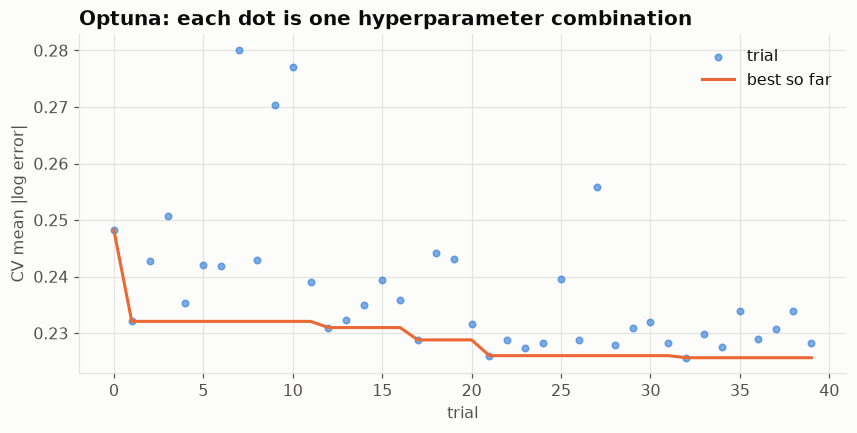

In [6]:
hist = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(hist["number"], hist["value"], s=18, color=SEQ, alpha=0.6, label="trial")
ax.plot(hist["number"], hist["value"].cummin(), color=SERIES[1], label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("CV mean |log error|")
ax.set_title("Optuna: each dot is one hyperparameter combination")
ax.legend()
fig.savefig(FIGURES / "fig10_optuna_history.png"); plt.show()

## 3 · Final comparison (cross-validated on the training set)

In [7]:
final = pd.concat([round2, pd.DataFrame([summarize("LightGBM · tuned", make_model("lightgbm", best_params))]
                                       ).set_index("model")])
final.to_csv(ROOT / "reports" / "model_comparison.csv")
MODELS.mkdir(exist_ok=True)
(MODELS / "best_params.json").write_text(json.dumps(best_params, indent=2))
final.style.format(FMT)

,mae_jod,rmse_jod,mape,median_ape,within_20pct,r2_log
model,,,,,,
Ridge (baseline),"3,463","8,443",31.7%,15.0%,62%,0.776
LightGBM · squared error,"3,532","8,248",32.0%,16.1%,60%,0.777
LightGBM · L1 (robust),"3,251","8,400",30.6%,13.2%,66%,0.784
LightGBM · Huber (robust),"3,208","8,168",30.6%,13.5%,66%,0.788
XGBoost · L1 (robust),"3,118","8,072",30.1%,12.9%,67%,0.793
LightGBM · tuned,"3,087","7,990",30.0%,12.8%,67%,0.794


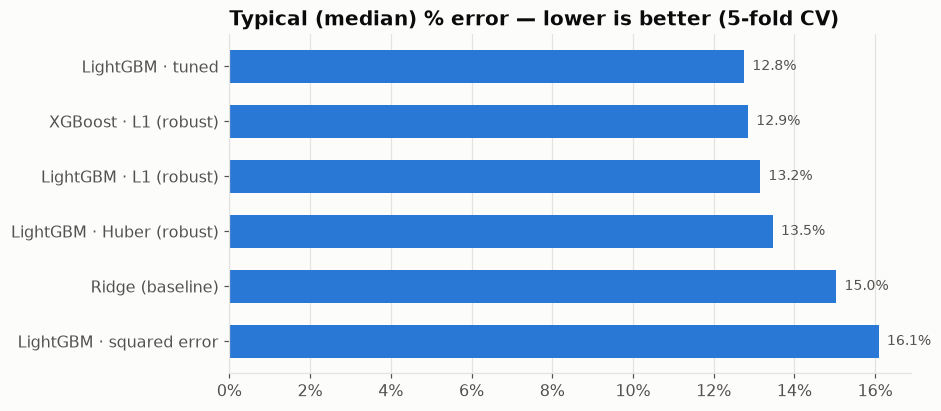

In [8]:
order = final.sort_values("median_ape", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(order.index, order["median_ape"], color=SEQ, height=0.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
for i, v in enumerate(order["median_ape"]):
    ax.text(v + 0.002, i, f"{v:.1%}", va="center", color=TEXT_2, fontsize=9)
ax.set_title("Typical (median) % error — lower is better (5-fold CV)")
fig.savefig(FIGURES / "fig11_model_comparison.png"); plt.show()

**Decision:** the tuned LightGBM is our model. Next: `python -m jocars.train` trains it on the full training set and
opens the **test set exactly once** for the final, honest score.